# PMLDL Assignment 2 (2026): Qwen3 Dense Decoder-Only Transformer

## Task description

Implement a small **decoder-only language model with the Qwen3 Dense architecture** in PyTorch and train it **from random initialization** to translate English into Portuguese. You will implement the architectural components yourself, then use the training and evaluation scaffold below.

The architecture reference for this assignment is **Qwen3 Dense**, specifically the full-attention design used by Qwen3-0.6B. “Dense” means that every token passes through the same feed-forward network in each layer. There are no experts or routing. Qwen2/Qwen2.5 and later Qwen variants are not interchangeable architecture specifications.

This is a scaled-down educational model: use a smaller vocabulary, hidden size, layer count, and context window. Reproducing Qwen's pretrained weights, large-scale training, chat template, or thinking behavior is not required. The task remains English → Portuguese translation.

## Architecture contract and references

Read the architecture section of the [Qwen3 Technical Report](https://arxiv.org/abs/2505.09388), the [official Qwen3 release](https://qwenlm.github.io/blog/qwen3/), and the [Qwen3-0.6B configuration](https://huggingface.co/Qwen/Qwen3-0.6B/blob/main/config.json). The [Transformers v4.51.3 Qwen3 implementation](https://github.com/huggingface/transformers/blob/v4.51.3/src/transformers/models/qwen3/modeling_qwen3.py) is a reference for conventions; write your own implementation and cite any resources you consult.

Your model must contain:

- One shared token vocabulary and embedding, followed by a stack of causal decoder blocks.
- Grouped-query attention (**GQA**) with fewer key/value heads than query heads.
- Per-head **QK-Norm** before rotary position embeddings (**RoPE**), applied to queries and keys only.
- **RMSNorm** before each attention/MLP sublayer, residual connections, and a final RMSNorm.
- A dense **SwiGLU** MLP. Attention and MLP projections have no bias.
- A vocabulary projection (LM head) producing next-token logits. Tie its weight to the token embedding, as in Qwen3-0.6B.

Use full causal attention in every block, with zero dropout for the baseline. Do not add an encoder, cross-attention, additive sinusoidal embeddings, embedding scaling by $\sqrt{d_{model}}$, or learned absolute position embeddings. KV caching is an optional optimization; correct generation by recomputing the prefix is sufficient.

## Allowed building blocks

You may use PyTorch tensor operations, autograd, `nn.Module`, `nn.ModuleList`, `nn.Parameter`, `nn.Linear`, `nn.Embedding`, `nn.SiLU`/`F.silu`, loss functions, and optimizers. Implement RMSNorm, RoPE, head grouping, attention scores, causal/padding masks, and the decoder blocks yourself.

Do not use `nn.Transformer*`, `nn.MultiheadAttention`, `F.scaled_dot_product_attention`, `nn.RMSNorm`, ready-made Qwen/Llama/other Transformer layers, or a pretrained language model. Do not copy a model implementation. Tokenization and dataset libraries are allowed.

## Submission

Provide your solution in **this notebook and submit it to Moodle**. Replace every `NotImplementedError` and complete the experiment/report cells. Run the completed notebook from a fresh kernel, save its outputs, and include:

- Your model implementation.
- The seed, package versions, device, data split sizes, tokenizer vocabulary size, model configuration, parameter count, training budget, and training/validation loss curves.
- Test loss, test perplexity, and **autoregressive corpus BLEU**; at least five test translations with English inputs and Portuguese references.
- A short discussion of differences from the original encoder–decoder Transformer, training behavior, errors, and limitations. State any departures from the scaffold.

Save the tokenizer and best validation checkpoint, and include code to reload them. If Moodle has a size limit, provide an accessible link to these artifacts in the notebook. Choose epochs and hyperparameters using validation data; evaluate the test set only after selecting the model.

## Grading criteria — 5 points

| Criterion | Points | Evidence |
| --- | ---: | --- |
| RMSNorm, RoPE, and dense SwiGLU | 1.0 | Correct formulas, tensor shapes, and bias settings |
| Causal GQA with QK-Norm | 1.0 | Separate Q/K/V projections, correct KV grouping, QK-Norm order, and causal/padding masks |
| Complete Qwen3 Dense causal LM | 1.0 | Pre-norm residual blocks, independent layer parameters, final RMSNorm, and tied LM head |
| Decoder-only translation and training | 1.0 | Correct sequence construction, target-only shifted loss, successful training, validation history, and checkpoint |
| Autoregressive evaluation and analysis | 1.0 | Test loss/perplexity, corpus BLEU, five translations, and a comparison of Qwen3 Dense with the classic Transformer |

After the submission deadline, an **in-person defence with TAs** will be arranged. You must demonstrate your model's English → Portuguese translation, explain your implementation and training/evaluation code, and answer questions about your solution.

## 1. Environment

The notebook contains intentional implementation gaps. Data preparation can run independently; training becomes runnable after you implement the required classes. A GPU is recommended for the experiment; use a smaller configuration for CPU debugging.

In [1]:
# НАШЕ ИЗМЕНЕНИЕ: зафиксировали проверенные версии библиотек данных и метрик.
# Уже установленный в Colab PyTorch не заменяем на CPU-сборку: нужен доступ к GPU.
# Красный текст в сохранённом pip-выводе относится к неиспользуемым здесь
# Transformers/cuDF. Это предупреждения совместимости, а не падение обучения.
# Keep Colab's existing GPU-enabled PyTorch; pin the data/evaluation stack tested here.
%pip install -q torch "datasets==5.1.0" "huggingface-hub==1.33.0" "tokenizers==0.22.2" "sacrebleu==2.6.0" tqdm matplotlib


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformers 5.20.2 requires tokenizers<0.24.0,>=0.23.1, but you have tokenizers 0.22.2 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [2]:
# НАШИ ДОПОЛНЕНИЯ: хеширование артефактов, JSON-отчёты, таймер и сведения о среде.
# Исходная установка SEED=42 и выбор CUDA/CPU уже были в шаблоне.
import hashlib
import importlib.metadata
import json
import math
import platform
import random
import time
from contextlib import nullcontext
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import sacrebleu
import torch
from IPython.display import Markdown, display
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    # Не подбираем алгоритм cuDNN заново по скорости для каждой формы.
    # Это не гарантирует побитовую одинаковость всех операций GPU.
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# НАШЕ ДОПОЛНЕНИЕ: сохраняем версии, устройство и seed, чтобы описать реальный запуск.
PACKAGE_VERSIONS = {name: importlib.metadata.version(name)
                    for name in ["torch", "datasets", "tokenizers", "sacrebleu",
                                 "tqdm", "matplotlib"]}
ENVIRONMENT = {"seed": SEED, "python": platform.python_version(),
               "packages": PACKAGE_VERSIONS, "device": str(device),
               "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
               "cuda": torch.version.cuda}
# НАШЕ ДОПОЛНЕНИЕ: читаемый размер графика и единое оформление; модель не меняется.
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
print(json.dumps(ENVIRONMENT, indent=2))
if device.type != "cuda":
    print("For the full experiment in Colab: Runtime > Change runtime type > T4 GPU.")
print("Seeded run; GPU kernels may still introduce small numerical differences.")


{
  "seed": 42,
  "python": "3.13.16",
  "packages": {
    "torch": "2.11.0+cu130",
    "datasets": "5.1.0",
    "tokenizers": "0.22.2",
    "sacrebleu": "2.6.0",
    "tqdm": "4.67.3",
    "matplotlib": "3.10.0"
  },
  "device": "cuda",
  "gpu": "Tesla T4",
  "cuda": "13.0"
}
Seeded run; GPU kernels may still introduce small numerical differences.


## 2. A small Qwen3 Dense configuration

All tensors use batch-first layout. Let $B$ be batch size, $T$ sequence length, $D$ hidden size, $H_q$ query head count, $H_{kv}$ key/value head count, $d_h$ head dimension, and $I$ MLP intermediate size. Require $H_q$ to be divisible by $H_{kv}$ and $d_h$ to be even.

Keep `head_dim` explicit: Qwen3 permits $H_q d_h \ne D$. Q maps $D \to H_q d_h$, K/V map $D \to H_{kv}d_h$, and the attention output projection maps $H_q d_h \to D$. The baseline below uses $H_q d_h=D$ for a small experiment. You may reduce width/depth for debugging, but keep GQA with $H_{kv}<H_q$ in the submitted model.

In [3]:
@dataclass
class QwenDenseConfig:
    vocab_size: int
    hidden_size: int = 256
    intermediate_size: int = 768
    num_hidden_layers: int = 4
    num_attention_heads: int = 8
    num_key_value_heads: int = 2
    head_dim: int = 32
    max_position_embeddings: int = 256
    rms_norm_eps: float = 1e-6
    rope_theta: float = 1_000_000.0
    tie_word_embeddings: bool = True

    def __post_init__(self):
        assert self.num_attention_heads % self.num_key_value_heads == 0
        assert self.num_key_value_heads < self.num_attention_heads
        assert self.head_dim % 2 == 0
        assert self.vocab_size > 0


## 3. Implement the components

### RMSNorm

For a vector $x$ of width $d$, use
$$\operatorname{RMSNorm}(x)=\gamma\odot\frac{x}{\sqrt{\frac{1}{d}\sum_{i=1}^{d}x_i^2+\epsilon}}.$$
Here $\gamma$ is a learned vector initialized to ones, $\epsilon$ prevents division by zero, and $\odot$ is elementwise multiplication. Compute the mean square in float32 for numerical stability, then restore the input dtype. Do not subtract the mean or add a bias. Hidden-state norms have width $D$; Q/K norms have width $d_h$ and share their learned scale across heads.

In [4]:
# НАША РЕАЛИЗАЦИЯ вместо NotImplementedError.
# RMSNorm нормирует масштаб последней оси, не вычитая среднее и не добавляя bias.
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        # Обучаемая gamma имеет размер dim; единицы изначально не меняют нормированный вектор.
        self.weight = nn.Parameter(torch.ones(dim))
        self.eps = eps

    def forward(self, x):
        # Float32 reduction prevents overflow/underflow in mixed precision.
        # Квадраты и среднее считаем в float32: в float16 легче получить переполнение.
        values = x.float()
        # rsqrt(z)=1/sqrt(z), поэтому это ровно x/sqrt(mean(x^2)+eps).
        # keepdim=True оставляет ось ширины 1 для корректного broadcasting.
        normalized = values * torch.rsqrt(values.square().mean(-1, keepdim=True) + self.eps)
        # Обучаем масштаб и возвращаем исходную точность для совместимости с AMP.
        return (normalized * self.weight.float()).to(x.dtype)


### Rotary position embeddings (RoPE)

Use the Qwen split-half convention. For position $p$ and $i=0,\ldots,d_h/2-1$, define $\theta_i=\text{rope\_theta}^{-2i/d_h}$ and angle $p\theta_i$. Duplicate the half-width angles to width $d_h$. With $\operatorname{rotate\_half}([a,b])=[-b,a]$ for equal-width halves,
$$\operatorname{RoPE}(x,p)=x\odot\cos(p\theta)+\operatorname{rotate\_half}(x)\odot\sin(p\theta).$$

Compute frequencies/angles in float32 on the input device, then cast cosine/sine to the Q/K dtype. Apply RoPE after QK-Norm, never to V. Use absolute positions starting at zero; generation must use the same position convention as training.

In [5]:
# НАША РЕАЛИЗАЦИЯ RoPE вместо TODO: положение кодируется поворотом Q и K, не V.
class RotaryEmbedding(nn.Module):
    def __init__(self, head_dim, theta=1_000_000.0):
        super().__init__()
        # Частоты theta^(-2i/dh) различаются для пар каналов; обучать их не требуется.
        inv_freq = theta ** (-torch.arange(0, head_dim, 2, dtype=torch.float32) / head_dim)
        # Buffer переносится вместе с моделью на GPU, но не является обучаемым параметром.
        # В checkpoint его можно не хранить: частоты восстанавливаются из config.
        self.register_buffer("inv_freq", inv_freq, persistent=False)

    def forward(self, q, k, position_ids):
        # [B,T,dh/2] -> duplicated split-half angles [B,1,T,dh].
        # Для частот, углов, sin/cos явно выключаем смешанную точность.
        with torch.autocast(device_type=q.device.type, enabled=False):
            half_angles = position_ids.float().unsqueeze(-1) * self.inv_freq.float()
            # [B,T,dh/2] -> [B,1,T,dh]. Ось 1 позволяет одни углы использовать во всех головах.
            angles = torch.cat((half_angles, half_angles), dim=-1).unsqueeze(1)
            cos, sin = angles.cos(), angles.sin()

        def rotate(x):
            # Qwen использует split-half: [a,b] превращается в [-b,a].
            # Это не чередование соседних чётных/нечётных элементов.
            first, second = x.chunk(2, dim=-1)
            rotated_half = torch.cat((-second, first), dim=-1)
            return x * cos.to(x.dtype) + rotated_half * sin.to(x.dtype)

        return rotate(q), rotate(k)


### Grouped-query causal attention and QK-Norm

Project hidden states to Q, K, V and reshape to $[B,H_q,T,d_h]$, $[B,H_{kv},T,d_h]$, $[B,H_{kv},T,d_h]$. Apply separate learned per-head RMSNorm modules to Q and K, then apply RoPE. Each KV head serves a consecutive group of $H_q/H_{kv}$ query heads; logically repeat K/V heads to match Q.

For query position $t$ and key position $s$, allow attention only when $s\le t$ **and** `attention_mask[b, s] == 1`. Here the mask is $[B,T]$, with 1 for real tokens and 0 for right padding. Apply this rule in every forward pass, including validation and generation. Compute
$$A=\operatorname{softmax}(QK^\top/\sqrt{d_h}+M),\qquad O=AV,$$
where $M$ is zero for allowed entries and $-\infty$ otherwise. Compute softmax in float32, cast back, concatenate query heads, and project to $D$. Right-padded queries can attend to preceding real tokens; their outputs are excluded from the loss. Every example below has a nonempty prompt, so no query needs an entirely masked row.

In [6]:
# НАША РЕАЛИЗАЦИЯ causal GQA + QK-Norm вместо TODO.
# B — batch; T — длина; D=256; Hq=8; Hkv=2; dh=32 в основном эксперименте.
class GroupedQueryAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.num_heads = config.num_attention_heads
        self.num_kv_heads = config.num_key_value_heads
        self.head_dim = config.head_dim
        # 8/2=4: каждая KV-голова обслуживает четыре последовательные Q-головы.
        self.groups = self.num_heads // self.num_kv_heads
        # Q: D -> Hq*dh, K/V: D -> Hkv*dh. Все проекции без bias по контракту Qwen3.
        # Не предполагаем Hq*dh == D: head_dim задан отдельно.
        self.q_proj = nn.Linear(config.hidden_size, self.num_heads * self.head_dim, bias=False)
        self.k_proj = nn.Linear(config.hidden_size, self.num_kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(config.hidden_size, self.num_kv_heads * self.head_dim, bias=False)
        self.o_proj = nn.Linear(self.num_heads * self.head_dim, config.hidden_size, bias=False)
        # Нормы Q/K имеют ширину dh, а не D; gamma каждой нормы общая для её голов.
        self.q_norm = RMSNorm(self.head_dim, config.rms_norm_eps)
        self.k_norm = RMSNorm(self.head_dim, config.rms_norm_eps)
        self.rope = RotaryEmbedding(self.head_dim, config.rope_theta)

    def forward(self, hidden_states, attention_mask, position_ids):
        batch, length, _ = hidden_states.shape
        # [B,T,D] -> Q[B,Hq,T,dh], K/V[B,Hkv,T,dh].
        # После transpose матричные операции выполняются независимо по batch и головам.
        q = self.q_proj(hidden_states).view(batch, length, self.num_heads, self.head_dim).transpose(1, 2)
        k = self.k_proj(hidden_states).view(batch, length, self.num_kv_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(hidden_states).view(batch, length, self.num_kv_heads, self.head_dim).transpose(1, 2)
        # One learned dh-wide scale per Q/K norm, shared across its heads.
        # Порядок обязателен: Q/K-проекции -> отдельный QK-Norm -> RoPE. Значения V не вращаем.
        q, k = self.rope(self.q_norm(q), self.k_norm(k), position_ids)
        # Группировка: KV0,KV0,KV0,KV0,KV1,KV1,KV1,KV1.
        # Явное повторение просто для проверки, но не реализует всю возможную экономию памяти GQA.
        k = k.repeat_interleave(self.groups, dim=1)
        v = v.repeat_interleave(self.groups, dim=1)

        # Скалярные произведения дают [B,Hq,T,T]. Деление на sqrt(dh) регулирует их масштаб.
        # Это масштабирование attention scores, а не запрещённое масштабирование embeddings.
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        positions = torch.arange(length, device=hidden_states.device)
        causal = positions[None, :] <= positions[:, None]  # key s <= query t
        # Разрешаем ключ s, только если s<=t и он не padding. Маски объединяются через AND.
        # Padding-запрос может смотреть назад, но его выход не участвует в loss.
        allowed = causal[None, None, :, :] & attention_mask[:, None, None, :].bool()
        # После softmax запрещённые позиции получают нулевую вероятность.
        # Непустой prompt гарантирует хотя бы один допустимый ключ в каждой строке.
        scores = scores.masked_fill(~allowed, float("-inf"))
        # Softmax считаем по ключам в float32, затем возвращаем точность Q для умножения на V.
        weights = torch.softmax(scores, dim=-1, dtype=torch.float32).to(q.dtype)
        # Взвешиваем V, возвращаем [B,T,Hq,dh] и делаем память непрерывной перед view.
        # Конкатенация голов и o_proj возвращают [B,T,D].
        attended = torch.matmul(weights, v).transpose(1, 2).contiguous()
        return self.o_proj(attended.view(batch, length, self.num_heads * self.head_dim))


### Dense SwiGLU and pre-norm decoder block

The MLP is $\operatorname{SwiGLU}(x)=W_{down}(\operatorname{SiLU}(W_{gate}x)\odot W_{up}x)$, with two projections $D\to I$ and one $I\to D$, all without bias. Every token uses this same MLP.

A decoder block computes
$$u=x+\operatorname{Attention}(\operatorname{RMSNorm}_1(x)),\qquad
y=u+\operatorname{SwiGLU}(\operatorname{RMSNorm}_2(u)).$$
The two sublayer norms have independent learned scales. Different decoder layers must also have independent parameters.

In [7]:
# НАША РЕАЛИЗАЦИЯ MLP и decoder block вместо TODO.
# Dense означает: одна и та же MLP для каждого токена, без выбора экспертов.
class SwiGLU(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.gate_proj = nn.Linear(config.hidden_size, config.intermediate_size, bias=False)
        self.up_proj = nn.Linear(config.hidden_size, config.intermediate_size, bias=False)
        self.down_proj = nn.Linear(config.intermediate_size, config.hidden_size, bias=False)

    def forward(self, x):
        # Две ветви D->I: SiLU(gate) поэлементно управляет признаками up.
        # down_proj возвращает I->D, чтобы residual можно было сложить со входом.
        return self.down_proj(F.silu(self.gate_proj(x)) * self.up_proj(x))


class QwenDenseDecoderLayer(nn.Module):
    def __init__(self, config):
        super().__init__()
        # Здесь нормируем скрытое состояние ширины D; нормы attention и MLP независимы.
        self.attention_norm = RMSNorm(config.hidden_size, config.rms_norm_eps)
        self.attention = GroupedQueryAttention(config)
        self.mlp_norm = RMSNorm(config.hidden_size, config.rms_norm_eps)
        self.mlp = SwiGLU(config)

    def forward(self, x, attention_mask, position_ids):
        # Pre-norm: сначала RMSNorm, затем подслой, затем residual-сложение.
        # Residual сохраняет прямой путь информации и градиента через глубину модели.
        x = x + self.attention(self.attention_norm(x), attention_mask, position_ids)
        return x + self.mlp(self.mlp_norm(x))


### Complete causal language model

Embed `input_ids`, pass through the decoder stack, apply final RMSNorm and the tied bias-free LM head. Return raw logits `[B, T, vocab_size]`; do not apply softmax before cross-entropy. Create positions `0, ..., T-1` for each right-padded example. Reject sequences longer than the configured context window.

Initialize linear/embedding weights from a normal distribution with standard deviation 0.02 and RMSNorm scales to one. Tie embedding/head weights after initialization. The scaffold applies the one-token shift externally, so `forward` must not shift tokens or labels.

In [8]:
# НАША СБОРКА полной causal LM вместо TODO: Embedding -> блоки -> RMSNorm -> LM head.
class QwenDenseForCausalLM(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.embed_tokens = nn.Embedding(config.vocab_size, config.hidden_size)
        # Создаём новый объект на каждой итерации: слои НЕ делят параметры.
        # ModuleList регистрирует их для optimizer, state_dict и переноса на устройство.
        self.layers = nn.ModuleList([QwenDenseDecoderLayer(config)
                                     for _ in range(config.num_hidden_layers)])
        self.final_norm = RMSNorm(config.hidden_size, config.rms_norm_eps)
        self.lm_head = nn.Linear(config.hidden_size, config.vocab_size, bias=False)
        # Веса Linear/Embedding ~ N(0,0.02); gamma RMSNorm = 1. Предобученные веса не загружаем.
        self.apply(self._initialize)
        if config.tie_word_embeddings:
            # Weight tying выполняем после инициализации: это один Parameter, не копия значений.
            # У 8000x256 embedding 2 048 000 весов; вторую независимую матрицу не создаём.
            self.lm_head.weight = self.embed_tokens.weight

    @staticmethod
    def _initialize(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
        elif isinstance(module, RMSNorm):
            nn.init.ones_(module.weight)

    def forward(self, input_ids, attention_mask=None):
        if input_ids.ndim != 2:
            raise ValueError("input_ids must have shape [batch, length]")
        batch, length = input_ids.shape
        if not 0 < length <= self.config.max_position_embeddings:
            raise ValueError("Sequence length must be positive and fit the context window")
        if attention_mask is None:
            attention_mask = torch.ones_like(input_ids)
        if attention_mask.shape != input_ids.shape:
            raise ValueError("attention_mask must have the same shape as input_ids")
        # Right padding and nonempty prompts guarantee at least one valid key.
        # Позиции 0..T-1 одинаково определены при обучении и при пересчёте префикса в генерации.
        position_ids = torch.arange(length, device=input_ids.device).expand(batch, -1)
        x = self.embed_tokens(input_ids)
        for layer in self.layers:
            x = layer(x, attention_mask, position_ids)
        # Возвращаем сырые logits [B,T,8000], без softmax и без сдвига labels.
        # Cross-entropy получает logits, а единственный сдвиг уже сделан в collate_fn шаблона.
        return self.lm_head(self.final_norm(x))


# НАШИ ДОПОЛНИТЕЛЬНЫЕ ПРОВЕРКИ: это маленькая случайная модель, не обучение переводчика.
def architecture_checks():
    # Small independent configuration also checks Hq * dh != hidden_size.
    # Временный seed внутри проверки не изменит внешний поток случайных чисел.
    with torch.random.fork_rng():
        torch.manual_seed(SEED)
        tiny = QwenDenseForCausalLM(QwenDenseConfig(
            vocab_size=23, hidden_size=12, intermediate_size=24,
            num_hidden_layers=2, num_attention_heads=4,
            num_key_value_heads=2, head_dim=4, max_position_embeddings=16)).eval()
        ids = torch.tensor([[2, 4, 6, 8, 10]])
        with torch.no_grad():
            logits = tiny(ids)
            changed = ids.clone()
            changed[:, 3:] = torch.tensor([11, 12])
            # Если меняем будущие токены, ранние logits должны остаться прежними: проверяем causality.
            torch.testing.assert_close(tiny(changed)[:, :3], logits[:, :3])
            padded_mask = torch.tensor([[1, 1, 1, 0, 0]])
            torch.testing.assert_close(tiny(ids, padded_mask)[:, :3], tiny(ids[:, :3]))
            # An ignored key must also be invisible to later real queries.
            key_mask = torch.tensor([[1, 0, 1, 1, 1]])
            changed = ids.clone()
            changed[0, 1] = 22
            # Меняем содержимое замаскированного ключа: последующие реальные запросы его не видят.
            torch.testing.assert_close(tiny(ids, key_mask)[:, 2:], tiny(changed, key_mask)[:, 2:])
        assert logits.shape == (1, 5, 23) and torch.isfinite(logits).all()
        assert tiny.lm_head.weight is tiny.embed_tokens.weight
        assert tiny.layers[0].attention.q_proj.weight is not tiny.layers[1].attention.q_proj.weight
        assert all(m.bias is None for m in tiny.modules() if isinstance(m, nn.Linear))
        norm = RMSNorm(2, eps=0.0)
        torch.testing.assert_close(norm(torch.tensor([[3., 4.]])),
                                   torch.tensor([[0.84852814, 1.13137085]]))
        zero_pos = torch.zeros(1, 1, dtype=torch.long)
        q = torch.randn(1, 4, 1, 4)
        k = torch.randn(1, 2, 1, 4)
        qr, kr = RotaryEmbedding(4)(q, k, zero_pos)
        torch.testing.assert_close(qr, q)
        torch.testing.assert_close(kr, k)
        # Техническая проверка autograd: у каждого параметра должен быть конечный градиент.
        # Это не loss основного эксперимента: здесь нет задачи перевода или сдвинутых целей.
        F.cross_entropy(tiny(ids).reshape(-1, 23), ids.reshape(-1)).backward()
        assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in tiny.parameters())
    print("Architecture checks passed: shapes, norms, RoPE, causality, padding, tying, gradients.")

architecture_checks()


Architecture checks passed: shapes, norms, RoPE, causality, padding, tying, gradients.


## 4. Translation as causal language modeling

Use one sequence per pair:

`<bos> <en> English tokens <pt> Portuguese tokens <eos>`

The prompt ends at `<pt>`. During teacher forcing, Portuguese tokens are available only to later positions through causal attention. Optimize next-token cross-entropy **only on Portuguese tokens and EOS**. The English prompt still participates in attention.

For full sequence `s` and prompt length `P`, construct full-length labels as `[-100] * P + s[P:]`. Feed `s[:-1]` to the model and compare its logits to `labels[1:]`. Thus the logit at `<pt>` predicts the first Portuguese token. `-100` means ignored by the loss; it is never an input token ID. Do not shift a second time inside the model.

Use [OPUS-100 en-pt](https://huggingface.co/datasets/Helsinki-NLP/opus-100) with its official train, validation, and test splits. The scaffold samples up to 50k/1k/1k pairs with a fixed seed and excludes normalized holdout sentences from training. The repository contains a much larger training split, so the budget can be increased for additional experiments.

In [9]:
from datasets import load_dataset
import unicodedata

# Keep the corpus-provided split boundaries. Never split the combined corpus.
# НАШЕ ДОПОЛНЕНИЕ: зафиксировали версию корпуса для воспроизводимости.
# Очистка, официальные split и исключение holdout из train уже были в шаблоне.
DATASET_REVISION = "805090dc28bf78897da9641cdf08b61287580df9"
corpus = load_dataset("Helsinki-NLP/opus-100", "en-pt", revision=DATASET_REVISION)

MAX_TRAIN_PAIRS = 50_000
MAX_VALIDATION_PAIRS = 1_000
MAX_TEST_PAIRS = 1_000

def normalized_text(text):
    return " ".join(unicodedata.normalize("NFKC", text).casefold().split())

def clean_pairs(rows, limit, excluded_en=None, excluded_pt=None):
    excluded_en = excluded_en or set()
    excluded_pt = excluded_pt or set()

    seen, result = set(), []

    for row in rows:
        en, pt = (row["translation"][lang].strip() for lang in ("en", "pt"))
        en_key, pt_key = normalized_text(en), normalized_text(pt)
        key = (en_key, pt_key)

        if not en_key or not pt_key or key in seen:
            continue

        if en_key in excluded_en or pt_key in excluded_pt:
            continue

        seen.add(key)
        result.append({"translation": {"en": en, "pt": pt}})

        if len(result) == limit:
            break

    return result

# Exclude all official holdout sentences, even those outside the evaluation budget.
holdout_en, holdout_pt = set(), set()

for split in ("validation", "test"):
    for row in corpus[split]:
        holdout_en.add(normalized_text(row["translation"]["en"]))
        holdout_pt.add(normalized_text(row["translation"]["pt"]))

train_pairs = clean_pairs(corpus["train"].shuffle(seed=SEED), MAX_TRAIN_PAIRS,
                          holdout_en, holdout_pt)
val_pairs = clean_pairs(corpus["validation"].shuffle(seed=SEED), MAX_VALIDATION_PAIRS)

val_en = {normalized_text(row["translation"]["en"]) for row in corpus["validation"]}
val_pt = {normalized_text(row["translation"]["pt"]) for row in corpus["validation"]}

test_pairs = clean_pairs(corpus["test"].shuffle(seed=SEED), MAX_TEST_PAIRS, val_en, val_pt)

assert len(train_pairs) == MAX_TRAIN_PAIRS

print({"train": len(train_pairs), "validation": len(val_pairs), "test": len(test_pairs)})
print("Source splits:", {split: len(rows) for split, rows in corpus.items()})


{'train': 50000, 'validation': 1000, 'test': 1000}
Source splits: {'test': 2000, 'train': 1000000, 'validation': 2000}


### A shared byte-level BPE tokenizer

To keep embedding/logit memory small, train an 8k tokenizer **using the training split only**, with both languages sharing one vocabulary. This replaces Qwen's production tokenizer; it does not change the decoder architecture. Special-token IDs are local to this tokenizer. Save it with the checkpoint.

The scaffold tokenizes each language separately and inserts boundary IDs explicitly. Use exactly the same prompt construction during training and generation.

In [10]:
from tokenizers import Tokenizer, models, pre_tokenizers, decoders, trainers

tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))

tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizer.decoder = decoders.ByteLevel()

special_tokens = ["<pad>", "<unk>", "<bos>", "<eos>", "<en>", "<pt>"]

trainer = trainers.BpeTrainer(
    vocab_size=8_000, min_frequency=2, special_tokens=special_tokens,
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
)

def training_texts():
    for pair in train_pairs:
        yield pair["translation"]["en"]
        yield pair["translation"]["pt"]

tokenizer.train_from_iterator(training_texts(), trainer=trainer)
pad_id, unk_id, bos_id, eos_id, en_id, pt_id = [
    tokenizer.token_to_id(t) for t in special_tokens
]

ARTIFACT_DIR = Path("assignment2_opus100_artifacts")

ARTIFACT_DIR.mkdir(exist_ok=True)
tokenizer.save(str(ARTIFACT_DIR / "tokenizer.json"))

print("Vocabulary:", tokenizer.get_vocab_size())

# НАШЕ ДОПОЛНЕНИЕ: хеш связывает checkpoint с точным tokenizer.json.
# Одинаковый размер словаря ещё не гарантирует одинаковое соответствие ID и токенов.
TOKENIZER_SHA256 = hashlib.sha256((ARTIFACT_DIR / "tokenizer.json").read_bytes()).hexdigest()
print("Artifacts:", ARTIFACT_DIR.resolve())
print("Tokenizer SHA256:", TOKENIZER_SHA256)


Vocabulary: 8000
Artifacts: /content/assignment2_opus100_artifacts
Tokenizer SHA256: 901efdc6643d615f88db462598a3c22e825f4c7647ec4547b2f44497b0a4df8a


### Length budget and batches

Use at most 96 English and 96 Portuguese tokens. Filter out longer or empty tokenized pairs rather than training on incomplete translations. The full sequence has at most 196 tokens and fits the 256-token context window. Report retained counts. These limits define the evaluation subset too; do not describe its score as a full-corpus score. Preserve the official corpus split boundaries. The scaffold excludes normalized exact holdout sentences from training; near-duplicates or noisy alignments can still remain.

In [11]:
MAX_SOURCE_TOKENS = 96
MAX_TARGET_TOKENS = 96
MAX_NEW_TOKENS = MAX_TARGET_TOKENS + 1  # Allow EOS after the longest target.

def make_prompt(english):
    return [bos_id, en_id] + tokenizer.encode(english).ids + [pt_id]

def encode_pairs(pairs):
    examples = []

    for pair in pairs:
        english, portuguese = (pair["translation"][lang] for lang in ("en", "pt"))
        source_ids = tokenizer.encode(english).ids
        target_ids = tokenizer.encode(portuguese).ids

        if not (0 < len(source_ids) <= MAX_SOURCE_TOKENS
                and 0 < len(target_ids) <= MAX_TARGET_TOKENS):
            continue

        prompt = make_prompt(english)
        sequence = prompt + target_ids + [eos_id]

        examples.append({
            "input_ids": sequence,
            "labels": [-100] * len(prompt) + target_ids + [eos_id],
            "prompt_ids": prompt,
            "english": english, "portuguese": portuguese,
        })

    return examples

train_examples = encode_pairs(train_pairs)
val_examples = encode_pairs(val_pairs)
test_examples = encode_pairs(test_pairs)

print({"retained_train": len(train_examples), "retained_validation": len(val_examples),
       "retained_test": len(test_examples)})

assert all([train_examples, val_examples, test_examples]), "A split became empty"

def collate_fn(examples):
    length = max(len(ex["input_ids"]) for ex in examples)
    ids = torch.full((len(examples), length), pad_id, dtype=torch.long)
    labels = torch.full_like(ids, -100)
    mask = torch.zeros_like(ids)

    for row, ex in enumerate(examples):
        n = len(ex["input_ids"])

        ids[row, :n] = torch.tensor(ex["input_ids"])
        labels[row, :n] = torch.tensor(ex["labels"])
        mask[row, :n] = 1

    return {"input_ids": ids[:, :-1], "attention_mask": mask[:, :-1],
            "labels": labels[:, 1:]}

BATCH_SIZE = 32

train_loader = DataLoader(train_examples, batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collate_fn,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_examples, batch_size=BATCH_SIZE, collate_fn=collate_fn)
test_loader = DataLoader(test_examples, batch_size=BATCH_SIZE, collate_fn=collate_fn)

example = train_examples[0]

print("Prompt:", tokenizer.decode(example["prompt_ids"], skip_special_tokens=False))
print("Supervised continuation:", tokenizer.decode(
    [t for t in example["labels"] if t != -100], skip_special_tokens=False))
print({k: tuple(v.shape) for k, v in next(iter(train_loader)).items()})

# НАШИ ПРОВЕРКИ к готовому collate_fn. Построение последовательности и masking уже были заданы.
# После единственного сдвига именно logit на <pt> должен предсказывать первый PT-токен.
# -100 — игнорируемая цель loss; передавать -100 в Embedding нельзя.
# Verify the single external shift: <pt> predicts the first target token.
check = collate_fn([example])
prompt_length = len(example["prompt_ids"])
assert (check["labels"][0, :prompt_length - 1] == -100).all()
assert check["input_ids"][0, prompt_length - 1].item() == pt_id
assert check["labels"][0, prompt_length - 1].item() == example["input_ids"][prompt_length]
assert check["labels"][0, -1].item() == eos_id
assert check["labels"].ne(-100).sum().item() == len(example["input_ids"]) - prompt_length

# НАШЕ ДОПОЛНЕНИЕ: фиксируем числа ДО и ПОСЛЕ фильтрации и отпечатки split.
# BLEU относится к 991 оставшемуся тестовому примеру, а не ко всему OPUS-100.
DATA_SUMMARY = {"dataset": "Helsinki-NLP/opus-100", "subset": "en-pt",
    "revision": DATASET_REVISION,
    "source_split_sizes": {split: len(rows) for split, rows in corpus.items()},
    "fingerprints": {split: rows._fingerprint for split, rows in corpus.items()},
    "sampled": {"train": len(train_pairs), "validation": len(val_pairs), "test": len(test_pairs)},
    "retained": {"train": len(train_examples), "validation": len(val_examples), "test": len(test_examples)},
    "max_source_tokens": MAX_SOURCE_TOKENS, "max_target_tokens": MAX_TARGET_TOKENS}
print("One-token shift and target-only supervision checks passed.")


{'retained_train': 49567, 'retained_validation': 984, 'retained_test': 991}
Prompt: <bos><en>What do I do?<pt>
Supervised continuation: O que faço?<eos>
{'input_ids': (32, 87), 'attention_mask': (32, 87), 'labels': (32, 87)}
One-token shift and target-only supervision checks passed.


## 5. Training and validation

Create a fresh model for this experiment. The scaffold averages loss over supervised tokens, clips gradients, and selects the checkpoint by validation loss. Set a realistic training budget, record it, and plot the history. One epoch is only a debugging run; report actual convergence behavior.

The baseline uses up to 50k training pairs and a maximum of 10 epochs. Stop after two epochs without a validation-loss improvement of at least 0.001. Save the best validation checkpoint even when training stops early.

In [12]:
# НАШИ ДОПОЛНЕНИЯ к готовому циклу обучения: повторный seed перед моделью,
# учёт параметров, AMP и перенос batch на фактическое устройство модели.
# AdamW, target-only cross-entropy, усреднение по токенам и clipping были в шаблоне.
# Fresh initialization: no pretrained language model or copied weights.
torch.manual_seed(SEED)
if device.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
config = QwenDenseConfig(vocab_size=tokenizer.get_vocab_size())
assert MAX_SOURCE_TOKENS + MAX_TARGET_TOKENS + 4 <= config.max_position_embeddings
model = QwenDenseForCausalLM(config).to(device)
# Вынесли в именованные константы; значения lr и weight_decay оставили из шаблона.
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.01
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
PARAMETER_COUNT = sum(p.numel() for p in model.parameters())

# CUDA AMP speeds up Colab T4 training; all sensitive reductions stay float32.
# На T4 используем float16 для подходящих операций; на CPU оставляем float32.
# GradScaler масштабирует loss, чтобы малые градиенты не исчезали в float16.
USE_AMP = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

def precision_context():
    return torch.autocast("cuda", dtype=torch.float16) if USE_AMP else nullcontext()

print(asdict(config))
print("Parameters:", f"{PARAMETER_COUNT:,}")
print("Training:", {"batch_size": BATCH_SIZE, "lr": LEARNING_RATE,
                    "weight_decay": WEIGHT_DECAY, "amp_float16": USE_AMP})

def batch_loss(model, batch):
    # Определяем устройство по самой модели, а не только по глобальной переменной device.
    model_device = next(model.parameters()).device
    batch = {k: v.to(model_device) for k, v in batch.items()}
    # Наш AMP-контекст оборачивает готовый расчёт logits и loss.
    # ignore_index=-100 и reduction='sum' сохраняют исходную target-only цель.
    with precision_context():
        logits = model(batch["input_ids"], attention_mask=batch["attention_mask"])
        labels = batch["labels"]
        loss_sum = F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                                   labels.reshape(-1), ignore_index=-100, reduction="sum")
    count = (labels != -100).sum().item()
    assert count > 0
    return loss_sum, count

@torch.no_grad()
def evaluate_loss(model, loader):
    model.eval()
    total_loss, total_tokens = 0.0, 0
    for batch in loader:
        loss_sum, count = batch_loss(model, batch)
        total_loss += loss_sum.item()
        total_tokens += count
    # НАША ЗАЩИТА от деления на ноль при пустой оценочной выборке.
    if not total_tokens:
        raise ValueError("Evaluation loader has no supervised target tokens")
    return total_loss / total_tokens

def train_epoch(model, loader, optimizer):
    model.train()
    total_loss, total_tokens = 0.0, 0
    for batch in tqdm(loader, desc="Training", leave=False, mininterval=2):
        optimizer.zero_grad(set_to_none=True)
        loss_sum, count = batch_loss(model, batch)
        loss = loss_sum / count
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss")
        scaler.scale(loss).backward()
        # Сначала возвращаем реальный масштаб градиентов, только затем clipping до нормы 1.
        # Иначе порог clipping применялся бы к искусственно увеличенным градиентам.
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        # При non-finite градиентах scaler может пропустить шаг и уменьшить масштаб.
        # На CPU scaler отключён, поэтому это обычное обновление optimizer.
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss_sum.item()
        total_tokens += count
    return total_loss / total_tokens


{'vocab_size': 8000, 'hidden_size': 256, 'intermediate_size': 768, 'num_hidden_layers': 4, 'num_attention_heads': 8, 'num_key_value_heads': 2, 'head_dim': 32, 'max_position_embeddings': 256, 'rms_norm_eps': 1e-06, 'rope_theta': 1000000.0, 'tie_word_embeddings': True}
Parameters: 5,065,216
Training: {'batch_size': 32, 'lr': 0.0003, 'weight_decay': 0.01, 'amp_float16': True}


{'epoch': 1, 'train_loss': 5.407779749073905, 'val_loss': 4.862734097555934, 'seconds': 63.329827045}


{'epoch': 2, 'train_loss': 4.292353546495741, 'val_loss': 4.238254006921836, 'seconds': 65.12765906600009}


{'epoch': 3, 'train_loss': 3.6560378685398636, 'val_loss': 3.7605119190783234, 'seconds': 62.636582786000076}


{'epoch': 4, 'train_loss': 3.1216530344118545, 'val_loss': 3.471042023054104, 'seconds': 62.15098938199992}


{'epoch': 5, 'train_loss': 2.735120953210599, 'val_loss': 3.304943075991143, 'seconds': 62.22580086800008}


{'epoch': 6, 'train_loss': 2.441886953112255, 'val_loss': 3.261694806805518, 'seconds': 62.690795509000054}


{'epoch': 7, 'train_loss': 2.192855625088386, 'val_loss': 3.255859127508724, 'seconds': 62.160356417}


{'epoch': 8, 'train_loss': 1.971331460806487, 'val_loss': 3.3235899381266734, 'seconds': 62.16183505599997}


{'epoch': 9, 'train_loss': 1.7636597291842693, 'val_loss': 3.424556257026214, 'seconds': 62.332407715000045}
Early stopping: two epochs without a validation improvement of at least 0.001.
Completed 9 epochs / 13,941 batches in 9.4 minutes; best validation loss 3.2559.


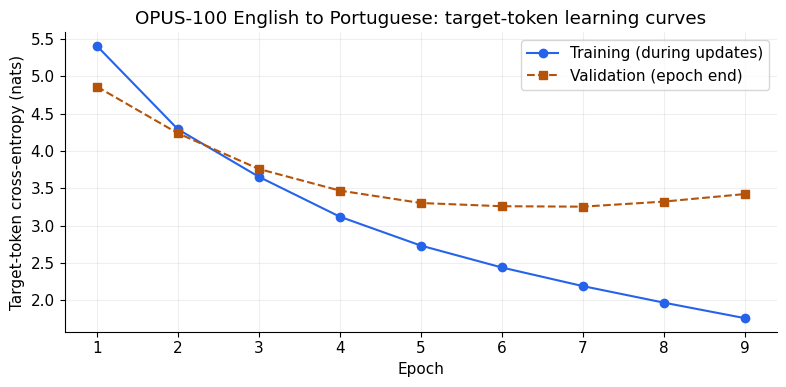

In [13]:
NUM_EPOCHS = 10
PATIENCE = 2
MIN_DELTA = 1e-3
history = []
best_val = float("inf")
stale_epochs = 0
# НАШЕ ДОПОЛНЕНИЕ: измеряем фактическое время обучения.
# Максимум 10 эпох, patience=2 и выбор checkpoint по validation уже были заданы.
training_started = time.perf_counter()

# НАШЕ ДОПОЛНЕНИЕ: сохраняем протокол эксперимента, чтобы числа можно было проверить.
RUN_METADATA = {"environment": ENVIRONMENT, "data": DATA_SUMMARY,
    "config": asdict(config), "parameter_count": PARAMETER_COUNT,
    "vocab_size": tokenizer.get_vocab_size(), "tokenizer_sha256": TOKENIZER_SHA256,
    "training_budget": {"max_epochs": NUM_EPOCHS, "batch_size": BATCH_SIZE,
        "max_steps": NUM_EPOCHS * len(train_loader), "lr": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY, "patience": PATIENCE, "min_delta": MIN_DELTA,
        "gradient_clip_norm": 1.0, "amp_float16": USE_AMP}}
(ARTIFACT_DIR / "run_metadata.json").write_text(json.dumps(RUN_METADATA, indent=2), encoding="utf-8")

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_started = time.perf_counter()
    train_loss = train_epoch(model, train_loader, optimizer)
    val_loss = evaluate_loss(model, val_loader)
    # НАША ПРОВЕРКА: не сохраняем повреждённый результат с NaN/Inf как лучший checkpoint.
    if not math.isfinite(val_loss):
        raise RuntimeError("Non-finite validation loss")
    previous_best = best_val
    history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
                    "seconds": time.perf_counter() - epoch_started})
    print(history[-1], flush=True)
    if val_loss < best_val:
        best_val = val_loss
        torch.save({"model": model.state_dict(), "config": asdict(config),
            "epoch": epoch, "val_loss": val_loss, "seed": SEED,
            # В исходный checkpoint с весами/config/эпохой добавили хеш токенизатора и метаданные.
            "tokenizer_sha256": TOKENIZER_SHA256, "metadata": RUN_METADATA},
            ARTIFACT_DIR / "best.pt")
    stale_epochs = 0 if val_loss < previous_best - MIN_DELTA else stale_epochs + 1
    # НАШЕ ДОПОЛНЕНИЕ: историю сохраняем после каждой эпохи, а не только печатаем.
    (ARTIFACT_DIR / "history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
    if stale_epochs >= PATIENCE:
        print("Early stopping: two epochs without a validation improvement of at least 0.001.")
        break

training_seconds = time.perf_counter() - training_started
print(f"Completed {len(history)} epochs / {len(history) * len(train_loader):,} batches "
      f"in {training_seconds / 60:.1f} minutes; best validation loss {best_val:.4f}.")
# НАШЕ ОФОРМЛЕНИЕ исходного графика: подписи, маркеры и сохранение PNG.
# На защите: validation минимален на 7-й эпохе, а на 8–9-й растёт при падении train.
fig, ax = plt.subplots()
ax.plot([r["epoch"] for r in history], [r["train_loss"] for r in history],
        marker="o", color="#2563eb", label="Training (during updates)")
ax.plot([r["epoch"] for r in history], [r["val_loss"] for r in history],
        marker="s", linestyle="--", color="#b45309", label="Validation (epoch end)")
ax.set(title="OPUS-100 English to Portuguese: target-token learning curves",
       xlabel="Epoch", ylabel="Target-token cross-entropy (nats)")
ax.set_xticks([r["epoch"] for r in history])
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(ARTIFACT_DIR / "loss_curves.png", dpi=160)
plt.show()


## 6. Autoregressive generation and held-out evaluation

At inference time the model receives **only the English prompt ending in `<pt>`**. Generate one token at a time, append it to the prefix, and stop at EOS or the declared token budget. Never pass a reference translation to this function. Keep the causal mask active. The baseline uses greedy decoding and recomputes the prefix.

Teacher-forced argmax predictions are not generated translations and must not be used for BLEU. For corpus BLEU, pass one list of hypotheses and a list containing the complete aligned reference stream: `sacrebleu.corpus_bleu(hypotheses, [references])`.

**Test loss** is the average next-token cross-entropy over Portuguese target tokens and EOS in the test set. English prompt tokens and padding are excluded. Test perplexity is `exp(test_loss)`.

In [14]:
# НАШИ ИЗМЕНЕНИЯ к готовой генерации: проверка бюджета/устройства, AMP,
# контроль соответствия checkpoint и tokenizer, экспорт результатов и отчёта.
# Greedy decoding, остановка по EOS, corpus BLEU и пять примеров были в шаблоне.
@torch.no_grad()
def translate_sentence(model, english, max_new_tokens=MAX_NEW_TOKENS):
    model.eval()
    prompt = make_prompt(english)
    # НАША ПРОВЕРКА: бессмысленный нулевой/отрицательный бюджет отклоняем.
    if not 0 < max_new_tokens:
        raise ValueError("max_new_tokens must be positive")
    if len(prompt) + max_new_tokens > model.config.max_position_embeddings:
        raise ValueError("Prompt and generation budget exceed the context window")
    # Наше дополнение позволяет использовать функцию и с загруженной на CPU моделью.
    model_device = next(model.parameters()).device
    ids = torch.tensor([prompt], dtype=torch.long, device=model_device)
    generated = []
    for _ in range(max_new_tokens):
        # Применяем ту же политику вычислительной точности, что и при обучении.
        with precision_context():
            logits = model(ids, attention_mask=torch.ones_like(ids))
        next_id = int(logits[0, -1].argmax().item())
        if next_id == eos_id:
            break
        generated.append(next_id)
        ids = torch.cat([ids, ids.new_tensor([[next_id]])], dim=1)
    return tokenizer.decode(generated, skip_special_tokens=True)

# Reload both artifacts; reject a checkpoint/tokenizer mismatch.
tokenizer = Tokenizer.from_file(str(ARTIFACT_DIR / "tokenizer.json"))
# После reload заново читаем ID: специальные ID локальны именно этому tokenizer.json.
pad_id, unk_id, bos_id, eos_id, en_id, pt_id = [tokenizer.token_to_id(t) for t in special_tokens]
checkpoint = torch.load(ARTIFACT_DIR / "best.pt", map_location=device, weights_only=True)
# Проверяем точное совпадение токенизатора: иначе веса соответствовали бы другим ID.
assert checkpoint["tokenizer_sha256"] == hashlib.sha256(
    (ARTIFACT_DIR / "tokenizer.json").read_bytes()).hexdigest()
config = QwenDenseConfig(**checkpoint["config"])
model = QwenDenseForCausalLM(config).to(device)
model.load_state_dict(checkpoint["model"])
# Дополнительно убеждаемся, что weight tying сохранился после загрузки.
assert model.lm_head.weight is model.embed_tokens.weight
print("Selected epoch:", checkpoint["epoch"])

# Test data first enter model evaluation here, after validation-only selection.
test_loss = evaluate_loss(model, test_loader)
test_perplexity = math.exp(test_loss)
hypotheses = [translate_sentence(model, ex["english"])
              for ex in tqdm(test_examples, desc="Autoregressive test translations", mininterval=2)]
references = [ex["portuguese"] for ex in test_examples]
bleu_metric = sacrebleu.metrics.BLEU()
bleu = bleu_metric.corpus_score(hypotheses, [references])
signature = str(bleu_metric.get_signature())

print("Test target-token loss:", test_loss)
print("Test target-token perplexity:", test_perplexity)
print("Autoregressive test corpus BLEU:", bleu.score)
print("BLEU signature:", signature)
for ex, hypothesis in list(zip(test_examples, hypotheses))[:5]:
    print("English:", ex["english"])
    print("Generated Portuguese:", hypothesis)
    print("Reference Portuguese:", ex["portuguese"])
    print()

# НАШ ЭКСПОРТ: сохраняем все 991 тройки, а не только пять примеров в выводе.
translations = [{"english": ex["english"], "reference": ex["portuguese"], "hypothesis": hyp}
                for ex, hyp in zip(test_examples, hypotheses)]
# НАША ДИАГНОСТИКА: пустые ответы, точные совпадения и повторы.
# Это поверхностные признаки, не семантическая accuracy.
# Проверка триграмм не ловит всю символьную/субсловную зацикленность.
empty_count = sum(not hyp.strip() for hyp in hypotheses)
exact_count = sum(normalized_text(hyp) == normalized_text(ref)
                  for hyp, ref in zip(hypotheses, references))
repetition_count = sum(any(words[i:i+3] == words[i+3:i+6]
                         for i in range(max(0, len(words)-5)))
                       for words in (hyp.split() for hyp in hypotheses))
metrics = {"selected_epoch": checkpoint["epoch"], "best_val_loss": checkpoint["val_loss"],
    "test_loss": test_loss, "test_perplexity": test_perplexity,
    "autoregressive_corpus_bleu": bleu.score, "bleu_signature": signature,
    "test_examples": len(test_examples), "max_new_tokens": MAX_NEW_TOKENS,
    "decoding": "greedy, prefix recomputation, causal attention",
    "epochs_completed": len(history), "training_seconds": training_seconds,
    "empty_hypotheses": empty_count, "normalized_exact_matches": exact_count,
    "adjacent_repeated_trigram_hypotheses": repetition_count}
(ARTIFACT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
(ARTIFACT_DIR / "test_translations.json").write_text(
    json.dumps(translations, ensure_ascii=False, indent=2), encoding="utf-8")

# НАШ АВТОМАТИЧЕСКИЙ ОТЧЁТ использует реально посчитанные history и метрики.
# 9.52 BLEU — не 9.52% правильно переведённых предложений.
# The experiment-specific discussion is derived from this run, never prefilled.
first, last = history[0], history[-1]
trend = ("Validation loss improved over the first epoch, consistent with learning on unseen pairs."
         if best_val < first["val_loss"] - MIN_DELTA else
         "Validation loss did not improve materially over the first epoch; this run gives little evidence of convergence.")
ending = ("The run exhausted its epoch budget; convergence is not established."
          if len(history) == NUM_EPOCHS else
          "Validation-based early stopping ended the run before the maximum budget.")
gap = ("At the last epoch validation loss exceeds the training loss, consistent with a generalization gap."
       if last["val_loss"] > last["train_loss"] else
       "At the last epoch validation loss does not exceed the online training loss; these use different model states.")
discussion = f"""### Observed experiment results

- Seed **{SEED}**; device **{ENVIRONMENT['gpu'] or ENVIRONMENT['device']}**;
  **{PARAMETER_COUNT:,}** unique trainable parameters; **{tokenizer.get_vocab_size():,}** vocabulary entries.
- Retained train/validation/test pairs: **{len(train_examples):,} / {len(val_examples):,} / {len(test_examples):,}**.
- Completed **{len(history)}** epochs in **{training_seconds / 60:.1f} minutes**;
  selected epoch **{checkpoint['epoch']}**, validation loss **{best_val:.4f}**.
- Target-token training loss: **{first['train_loss']:.4f} → {last['train_loss']:.4f}**;
  validation loss: **{first['val_loss']:.4f} → {last['val_loss']:.4f}**.
- Test target-token loss **{test_loss:.4f}**, perplexity **{test_perplexity:.2f}**,
  autoregressive corpus BLEU **{bleu.score:.2f}** on the declared filtered test subset.

{trend} {ending} {gap} Training loss averages batches while weights change;
validation uses the fixed epoch-end model, so their difference is descriptive.

### Observed output diagnostics

Among **{len(hypotheses)}** generated translations, **{empty_count}** are empty,
**{exact_count}** exactly match their reference after case/whitespace normalization,
and **{repetition_count}** contain an immediately repeated three-word span.
These are surface diagnostics, not measures of semantic correctness. The five
examples above expose actual lexical choices, omissions, agreement errors and
repetition for inspection; the complete aligned outputs are saved to
`test_translations.json`. BLEU measures corpus n-gram overlap with one reference;
valid paraphrases can score poorly, while fluent but unfaithful outputs can still
share n-grams. Teacher-forced perplexity alone cannot establish translation quality.
"""
display(Markdown(discussion))
(ARTIFACT_DIR / "experiment_discussion.md").write_text(discussion, encoding="utf-8")

# Colab runtimes are temporary. Download this bundle and save the executed notebook.
# НАШЕ СОХРАНЕНИЕ АРТЕФАКТОВ: Colab-сессия временная, поэтому нужен внешний ZIP.
# Сохранённые output ноутбука не содержат сами обученные веса best.pt.
import shutil
bundle_path = shutil.make_archive(str(ARTIFACT_DIR), "zip", root_dir=ARTIFACT_DIR)
print("Saved checkpoint, tokenizer, metadata, history, curves, translations and report:", bundle_path)
try:
    from google.colab import files
except ImportError:
    print("Outside Colab: copy the ZIP and this executed notebook to persistent storage.")
else:
    files.download(bundle_path)


Selected epoch: 7


Test target-token loss: 3.3053258281973634
Test target-token perplexity: 27.25742137855214
Autoregressive test corpus BLEU: 9.518995846291961
BLEU signature: nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0
English: - Mery Christmas Mr Stewart.
Generated Portuguese: - Mois Christmas Mr Stewart.
Reference Portuguese: - Feliz Natal, Sr. Stewart.

English: Sorry, homey.
Generated Portuguese: Desculpa, para casa.
Reference Portuguese: Boa tentativa, amigo.

English: You can't tell what's inside!
Generated Portuguese: Não pode dizer o que está dentro!
Reference Portuguese: Mas não dá pra saber qual tem dentro!

English: In this respect the recommendations of the Rome-PE report should be implemented and internal financial control improved.
Generated Portuguese: Neste contexto, o relatório da delegação do Rome e da política financeira.
Reference Portuguese: Neste sentido, as recomendações do relatório "ROME-PE" devem ser postas em prática e o controlo interno da gestão financeira de

### Observed experiment results

- Seed **42**; device **Tesla T4**;
  **5,065,216** unique trainable parameters; **8,000** vocabulary entries.
- Retained train/validation/test pairs: **49,567 / 984 / 991**.
- Completed **9** epochs in **9.4 minutes**;
  selected epoch **7**, validation loss **3.2559**.
- Target-token training loss: **5.4078 → 1.7637**;
  validation loss: **4.8627 → 3.4246**.
- Test target-token loss **3.3053**, perplexity **27.26**,
  autoregressive corpus BLEU **9.52** on the declared filtered test subset.

Validation loss improved over the first epoch, consistent with learning on unseen pairs. Validation-based early stopping ended the run before the maximum budget. At the last epoch validation loss exceeds the training loss, consistent with a generalization gap. Training loss averages batches while weights change;
validation uses the fixed epoch-end model, so their difference is descriptive.

### Observed output diagnostics

Among **991** generated translations, **0** are empty,
**17** exactly match their reference after case/whitespace normalization,
and **22** contain an immediately repeated three-word span.
These are surface diagnostics, not measures of semantic correctness. The five
examples above expose actual lexical choices, omissions, agreement errors and
repetition for inspection; the complete aligned outputs are saved to
`test_translations.json`. BLEU measures corpus n-gram overlap with one reference;
valid paraphrases can score poorly, while fluent but unfaithful outputs can still
share n-grams. Teacher-forced perplexity alone cannot establish translation quality.


Saved checkpoint, tokenizer, metadata, history, curves, translations and report: /content/assignment2_opus100_artifacts.zip


## 7. Report and discussion

### Русская учебная версия: что в ней изменено

Комментарии добавлены 5 ноября 2026 года к нашему решению, а не к неизменённым
частям задания. Пометки «НАША РЕАЛИЗАЦИЯ» обозначают заполненные TODO;
«НАШЕ ДОПОЛНЕНИЕ» — проверки, воспроизводимость, AMP и сохранение артефактов.
Вычислительный Python-код идентичен полному запуску 24 октября 2026 года:
добавлены только комментарии. Все 33 исходные ячейки, их порядок и настоящие
выводы сохранены. Повторное полное обучение ради комментариев не запускалось.
Текст ниже — русское пояснение нашего итогового отчёта и памятка для защиты.

### Что было задано, а что реализовали мы

Изначально были даны архитектурный контракт, `QwenDenseConfig`, очистка и
разделение OPUS-100, обучение BPE, сборка последовательностей, `collate_fn`,
основной цикл обучения/early stopping, greedy-генерация и расчёт BLEU.
Поэтому нельзя говорить, что весь этот конвейер был написан нами с нуля.

Наше основное задание — заполнить `RMSNorm`, `RotaryEmbedding`,
`GroupedQueryAttention`, `SwiGLU`, `QwenDenseDecoderLayer` и
`QwenDenseForCausalLM`. Кроме этого, мы добавили проверки, фиксацию версий,
метаданные, смешанную точность, проверку связи tokenizer/checkpoint,
экспорт истории/метрик/переводов и этот анализ.

### Идея задачи и обучение переводу

Мы обучаем **с нуля маленькую модель архитектуры Qwen3 Dense**, а не загружаем
предобученный Qwen. Один словарь используется для английского и португальского.
Для каждой пары строится последовательность:

`<bos> <en> English <pt> Português <eos>`

Модель всегда предсказывает следующий токен. Английская часть задаёт условие,
а loss считается только по португальским токенам и EOS. Схематический пример
(здесь слова условно считаются одним токеном, настоящий BPE может разбить их):

```text
Полная последовательность: BOS  EN  Hello  PT   Olá  EOS
Вход модели:              BOS  EN  Hello  PT   Olá
Цели после сдвига:        -100 -100 -100   Olá  EOS
```

Именно выход на позиции `<pt>` предсказывает первый токен перевода.
`-100` — игнорируемая цель cross-entropy, а не ID, подаваемый в Embedding.
Сдвиг выполнен один раз в `collate_fn`; внутри `forward` повторять его нельзя.
Отсутствие прямого loss на английских позициях не отключает обучение их
представлений: через attention на них поступает градиент целевой ошибки.

### Ключевые части модели и почему они такие

1. **Embedding.** Из ID `[B,T]` получаем векторы `[B,T,256]`. Масштабирование
   на sqrt(D) и добавочные абсолютные позиции здесь не нужны по контракту.
2. **RMSNorm.** Делим вектор на `sqrt(mean(x**2)+eps)` и умножаем на обучаемую
   gamma. Среднее не вычитаем; bias нет. Редукцию считаем в float32 ради
   численной устойчивости. Норма hidden state имеет ширину D=256, Q/K — dh=32.
3. **GQA.** Для восьми Q-голов создаём две KV-головы. Каждая KV-голова
   обслуживает четыре соседние Q-головы. Это уменьшает размер K/V-проекций;
   наше явное повторение голов не экономит всю возможную память attention.
4. **QK-Norm и RoPE.** Сначала отдельные нормы Q/K, затем поворот каналов
   в зависимости от позиции. Порядок задан архитектурой. V не вращаем.
   Split-half означает `[a,b] -> [-b,a]`, а не перестановку соседних каналов.
5. **Attention.** Считаем `softmax(Q @ K.T / sqrt(dh) + mask) @ V`.
   Матрица scores имеет форму `[B,8,T,T]`. Разрешены только ключи из прошлого
   или текущей позиции, которые не padding. Иначе модель увидела бы правильное
   продолжение из будущего и обучалась бы на недоступной при генерации информации.
6. **SwiGLU.** `down(SiLU(gate(x))*up(x))` расширяет ширину 256->768,
   поэлементно управляет признаками и возвращает 768->256. Это одна плотная MLP,
   не смесь экспертов. Все Linear без bias.
7. **Pre-norm и residual.** Перед каждым подслоем нормируем вход, а результат
   прибавляем к прежнему состоянию. Это сохраняет прямой путь для информации
   и градиента. Четыре слоя имеют независимые параметры.
8. **Final RMSNorm и LM head.** Получаем logits `[B,T,8000]` без softmax.
   Cross-entropy сама выполняет нужную нормализацию. Выходная матрица и Embedding
   используют один Parameter: weight tying, а не две одинаковые копии.

В отличие от классического encoder–decoder Transformer, здесь нет отдельного
двунаправленного английского энкодера и cross-attention. Источник и перевод
обрабатываются одним causal decoder. В классическом варианте использовались
LayerNorm, ReLU-MLP и additive positional encodings; здесь RMSNorm, SwiGLU,
QK-Norm и RoPE. Само связывание выходных/входных embedding не является уникальным
изобретением Qwen3: оно обсуждалось и в исходном Transformer.

### Данные, бюджет и реальные результаты

Корпус — официальный OPUS-100 en-pt: 1 000 000 train и по 2 000 validation/test
примеров до выборки. Использовали до 50 000/1 000/1 000 пар, сохранив исходные
границы. После очистки и ограничения 96 английских/96 португальских BPE-токенов
осталось **49 567 / 984 / 991**. Длинные пары исключаются, не обрезаются:
иначе мы учили бы неполный перевод. Точные нормализованные holdout-предложения
исключены из train; близкие дубликаты и шум всё ещё возможны. Токенизатор
с общим словарём 8 000 единиц обучен только на train.

Конфигурация: D=256, I=768, 4 слоя, Hq=8, Hkv=2, dh=32, контекст 256,
нулевой dropout, **5 065 216** уникальных параметров. Эти размеры и основные
гиперпараметры уже предлагались в шаблоне; отдельный поиск лучших размеров не
проводился. Seed=42; AdamW: lr=0.0003, weight_decay=0.01, batch=32,
gradient clipping=1. На Tesla T4 использовались autocast float16 и GradScaler;
перед clipping градиенты возвращаются в реальный масштаб через `unscale_`.

| Показатель | Результат полного запуска |
| --- | ---: |
| Выполнено эпох | 9 из максимальных 10 |
| Выбрана эпоха | 7 |
| Лучший validation loss | 3.2559 |
| Test loss | 3.3053 |
| Test perplexity | 27.2574 |
| Autoregressive corpus BLEU | 9.5190 |
| Тестовых переводов | 991 |
| Время обучения | 565.1 с, около 9.4 мин |

Training loss снизился с 5.4078 до 1.7637. Validation loss достиг минимума
3.2559 на эпохе 7, затем вырос до 3.3236 и 3.4246. Это признак переобучения:
ошибка на обучающих примерах ещё падает, но на новых уже растёт. Поэтому после
двух эпох без достаточного улучшения остановились и загрузили эпоху 7, а не 9.
График находится в выводе раздела 5. Онлайн training loss и validation loss
измерены при разных состояниях весов, что нужно учитывать при сравнении.

Test использовался после выбора checkpoint по validation. Test loss — средняя
отрицательная log-вероятность правильных португальских токенов/EOS;
perplexity = exp(loss). **27.26 — не процент ошибок.** BLEU оценивает совпадение
корпусных n-грамм с одним эталонным потоком и учитывает длину.
**9.52 BLEU — не 9.52% правильно переведённых предложений.** Это скромное
качество: работа показывает корректно обучаемую архитектуру, а не готовый
качественный переводчик. Результат относится к отфильтрованным 991 примеру,
не к полному корпусу. Подпись SacreBLEU:
`nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0`.

### Генерация и разбор примеров

При teacher forcing на обучении правильные предыдущие PT-токены известны,
но causal mask закрывает будущие. При настоящем переводе передаём только
английский prompt до `<pt>`. Далее выбираем argmax последнего logit-вектора,
добавляем выбранный токен к префиксу и повторяем до EOS или 97 новых токенов.
Префикс пересчитывается полностью: KV cache не реализован, это допустимо,
но медленнее. Нельзя подменять такую генерацию argmax-ответами при поданных
эталонных предыдущих токенах: тогда оценка не отражала бы реальное применение.

В сохранённом выводе раздела 6 уже есть пять троек English / Generated / Reference:

- `You can't tell what's inside!` -> `Não pode dizer o que está dentro!`:
  пример осмысленного перевода с формулировкой, отличной от эталона.
- `Sorry, homey.` -> `Desculpa, para casa.`: разговорное обращение
  переведено неверно; модель, возможно, связала его со словом home.
- Рождественское поздравление частично копируется по-английски, появляется
  некорректное `Mois` вместо полноценного перевода поздравления.
- Длинная фраза про Rome-PE теряет рекомендации и требование внутреннего
  финансового контроля; формально похожее предложение не сохраняет смысл.
- В примере с датой создания появляются выдуманное слово и повторяющиеся
  фрагменты времени: пример авторегрессионного зацикливания.

Среди 991 ответа: 0 пустых, 17 точных нормализованных совпадений и 22 ответа
с немедленно повторённой словесной триграммой. Это диагностические счётчики,
не семантическая accuracy; проверка триграмм пропускает часть символьных повторов.
Небольшая модель, ограниченный и шумный корпус, одна reference и greedy decoding
ограничивают качество. Изменения модели/бюджета надо выбирать по validation,
не подгонять к уже увиденному test.

### Что показать на защите: порядок на 5–7 минут

1. **Сформулировать задачу.** Маленький Qwen3 Dense decoder-only, обучение
   с нуля, английский -> португальский. Не предобученный Qwen и не encoder–decoder.
2. **Открыть разделы 2–3.** Показать config, RMSNorm, порядок QK-Norm -> RoPE,
   группировку голов, causal/padding mask, SwiGLU, residual и weight tying.
   Уметь назвать формы Q/K/V, scores и выходных logits.
3. **Показать раздел 4.** Объяснить prompt, `-100`, единственный сдвиг и то,
   почему `<pt>` предсказывает первый токен перевода. Разделить train/val/test.
4. **Показать вывод раздела 5.** График и эпохи 7–9: почему early stopping
   выбрал более ранние веса, хотя train loss продолжал падать.
5. **Показать вывод раздела 6.** Test loss/perplexity/BLEU и минимум пять
   реальных переводов. Честно разобрать удачный пример, потерю смысла и повторы.
6. **Сделать живой перевод.** Загрузить best.pt и tokenizer.json, ввести
   английскую фразу без эталона и вызвать генерацию. Повторное обучение для
   показа уже обученной модели не требуется.

На вопросы «почему 9, а не 10 эпох?» / «почему не последняя модель?» ответ:
patience=2, validation ухудшился после эпохи 7, потому выбрана эпоха 7.
На вопрос «какую часть сделали сами?» показать помеченные реализации и
отличать их от готовых данных/цикла обучения из шаблона.

### Быстрый показ перевода без повторного обучения

Сохранённые outputs видны без ядра, но **для нового перевода нужны работающие
Python-классы, tokenizer.json и best.pt**. Если старая Colab-сессия закрылась,
открыть новый runtime, выполнить установку библиотек, импорты и только ячейки
с config/классами модели (до `architecture_checks()` включительно). Загрузку
корпуса и обучение разделов 4–5 запускать для этой демонстрации не нужно.

Загрузить ZIP в текущую папку Colab. Следующий фрагмент можно выполнить
в отдельном временном scratch cell: он восстановит модель и переведёт фразу,
не изменяя структуру этого ноутбука. Это та же схема greedy generation;
на CPU она тоже работает, обычно медленнее.

```python
# Выполнять после ячеек с импортами, QwenDenseConfig и классами модели.
# Переобучение и загрузка OPUS-100 здесь НЕ нужны.
from contextlib import nullcontext
from pathlib import Path
from tokenizers import Tokenizer
import hashlib
import zipfile

ARTIFACT_DIR = Path("assignment2_opus100_artifacts")
if not (ARTIFACT_DIR / "best.pt").exists():
    # Сначала загрузить assignment2_opus100_artifacts.zip в текущую папку Colab.
    with zipfile.ZipFile("assignment2_opus100_artifacts.zip") as archive:
        archive.extractall(ARTIFACT_DIR)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = Tokenizer.from_file(str(ARTIFACT_DIR / "tokenizer.json"))
bos_id, en_id, pt_id, eos_id = [tokenizer.token_to_id(t)
                               for t in ("<bos>", "<en>", "<pt>", "<eos>")]
checkpoint = torch.load(ARTIFACT_DIR / "best.pt", map_location=device, weights_only=True)
assert hashlib.sha256((ARTIFACT_DIR / "tokenizer.json").read_bytes()).hexdigest() == checkpoint["tokenizer_sha256"]
model = QwenDenseForCausalLM(QwenDenseConfig(**checkpoint["config"])).to(device)
model.load_state_dict(checkpoint["model"])
model.eval()

@torch.no_grad()
def demo_translate(english, max_new_tokens=97):
    prompt = [bos_id, en_id] + tokenizer.encode(english).ids + [pt_id]
    if max_new_tokens <= 0 or len(prompt) + max_new_tokens > model.config.max_position_embeddings:
        raise ValueError("Фраза или бюджет генерации не помещаются в контекст")
    ids = torch.tensor([prompt], dtype=torch.long, device=device)
    generated = []
    for _ in range(max_new_tokens):
        precision = (torch.autocast("cuda", dtype=torch.float16)
                     if device.type == "cuda" else nullcontext())
        with precision:
            logits = model(ids, attention_mask=torch.ones_like(ids))
        next_id = int(logits[0, -1].argmax())
        if next_id == eos_id:
            break
        generated.append(next_id)
        ids = torch.cat((ids, ids.new_tensor([[next_id]])), dim=1)
    return tokenizer.decode(generated, skip_special_tokens=True)

print("Загружена эпоха:", checkpoint["epoch"])
print(demo_translate("You can't tell what's inside!"))
# Можно заменить английскую фразу своей; качество не гарантируется.
```

**Что хранится после запуска.** В самом ноутбуке — тексты выводов, график,
метрики, пять примеров и отчёт. В `assignment2_opus100_artifacts.zip` —
`best.pt`, `tokenizer.json`, `history.json`, `run_metadata.json`,
`metrics.json`, `test_translations.json` (все 991 перевода),
`loss_curves.png` и `experiment_discussion.md`. Сохранённый вывод не заменяет
файл весов. Распаковка в `assignment2_opus100_artifacts/` нужна для reload.
Исходный запуск сохранён в
[Colab](https://colab.research.google.com/github/MedvAx-AI/qwen3-en-pt-from-scratch/blob/main/notebooks/experiment.ipynb),
но учебная копия с русскими комментариями создана отдельно и не меняет его.

### Ограничения и источники

Это учебный масштаб с собственной 8k BPE, не производственный Qwen.
Сохранены full causal attention, GQA, QK-Norm, tied weights и baseline-размеры.
Наши дополнения к scaffold: AMP с устойчивыми редукциями, проверки,
фиксированные версии, хеш токенизатора, протокол и экспорт результатов.
Даже с seed возможны небольшие численные различия GPU.

Архитектурные конвенции проверялись по:

- [Qwen3 Technical Report](https://arxiv.org/html/2505.09388v1#S2).
- [Официальный выпуск Qwen3](https://qwenlm.github.io/blog/qwen3/).
- [Конфигурация Qwen3-0.6B](https://huggingface.co/Qwen/Qwen3-0.6B/blob/main/config.json).
- [Transformers v4.51.3 Qwen3](https://github.com/huggingface/transformers/blob/v4.51.3/src/transformers/models/qwen3/modeling_qwen3.py)
  — RoPE, последовательная группировка KV и порядок QK-Norm; готовый слой не импортируется.
- [OPUS-100](https://huggingface.co/datasets/Helsinki-NLP/opus-100).
- [Установка PyTorch](https://pytorch.org/get-started/locally/).
